# Lab 02 — Transfer learning trên CIFAR-10
Bảng, biểu đồ và nhận xét nằm trực tiếp trong notebook. Run hiện hành được đọc từ registry; LAB02_RUN chọn một run riêng để kiểm chứng.

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p/'src/notebook_views.py').exists())
sys.path.insert(0, str(ROOT))
from src import notebook_views as view, merged_results as merged
ROOT, RUN, OUT = merged.context()
merged.explain(RUN, 'intro')

Run đang xem: `20261027T140405Z_cifar10_gpu_tuning_group_02_ec77fa72`. Ảnh 224×224, seed 42. Gộp các nhóm trong registry; 18 fine-trial.

Chọn bằng validation accuracy/loss/time; test chỉ để báo cáo sau lựa chọn. Thời gian fit trial được chọn khác tổng chi phí search.

## 1. Kết quả và chi phí
Accuracy tolerance 0,001 = 0,1 điểm phần trăm; loss tolerance 0,005. Không dùng test để chọn. Head học trên pooled feature cache, fine-tune xử lý ảnh hoặc cache prefix theo cấu hình đã lưu.

,model,stage,accuracy,loss,macro_f1,macro_precision,macro_recall,best_val_accuracy
0,resnet18,head,0.8586,0.40243,0.85901,0.86153,0.8586,0.8704
1,resnet18,finetune,0.9371,0.30512,0.93709,0.93719,0.9371,0.9406
2,densenet121,head,0.8790,0.34426,0.87911,0.87986,0.8790,0.8890
3,densenet121,finetune,0.9461,0.20447,0.94592,0.94621,0.9461,0.9478


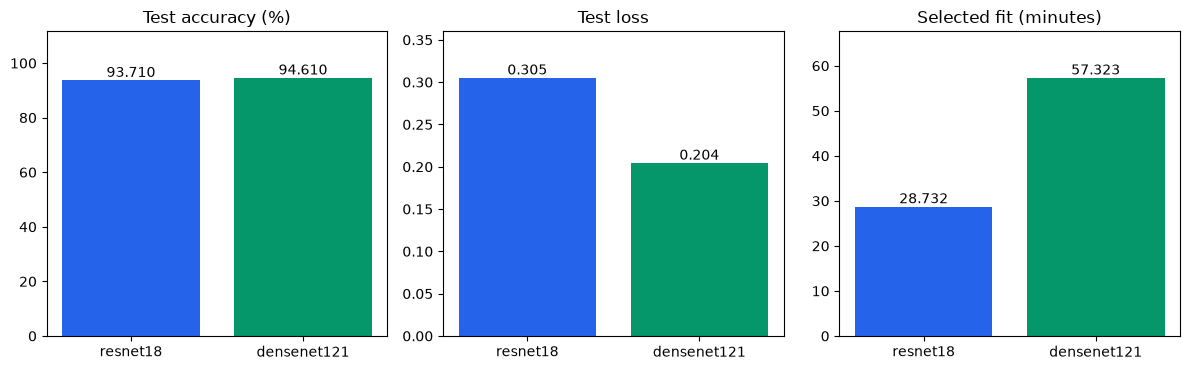

,model,selected_fit_minutes,all_fine_trials_hours
1,resnet18,28.732,6.026
3,densenet121,57.323,12.807


**resnet18**: test accuracy 93.71%, loss 0.3051, Macro F1 0.9371; tăng 7.85 điểm % so với head; fit fine-tune 28.73 phút.

**densenet121**: test accuracy 94.61%, loss 0.2045, Macro F1 0.9459; tăng 6.71 điểm % so với head; fit fine-tune 57.32 phút.

Một seed chưa đủ khẳng định ưu thế thống kê. Không so throughput head cache với fine-tune ảnh đầy đủ.

In [2]:
merged.summary(ROOT, OUT, RUN)
merged.explain(RUN, 'quality')

## 2. Kiến trúc và các tầng được mở
Head khóa backbone; fine-tune điều chỉnh đặc trưng cấp cao ở các block cuối. Bảng dưới ghi đúng phạm vi mở tầng của run đang xem. BatchNorm giữ running statistics cố định. Các run đã lưu dùng weight decay 1e-4, không dropout hoặc augmentation ngẫu nhiên; chuẩn hóa ImageNet.

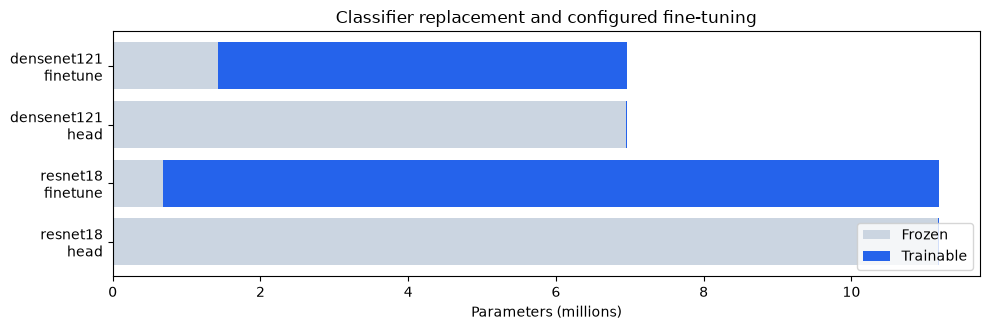

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,10498570,layer3 + layer4 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,5534474,denseblock3 + transition3 + denseblock4 + norm...


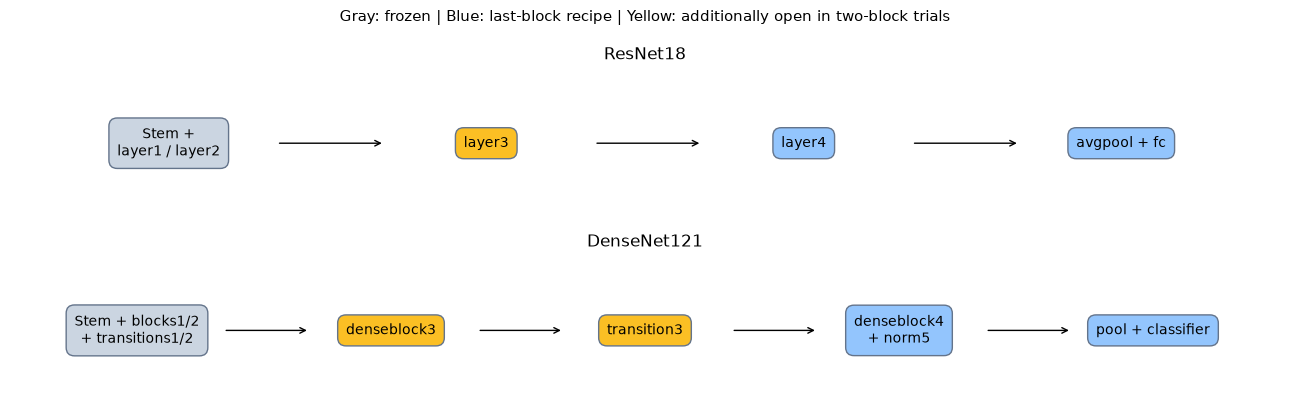

In [3]:
view.architecture_visual(RUN, OUT)

## 3. Head search: learning rate và batch
Hình thể hiện các LR/batch thực sự đã thử trong run này. Mỗi candidate dùng cùng initialization và seed shuffle; head search được đếm riêng với fine-tune.

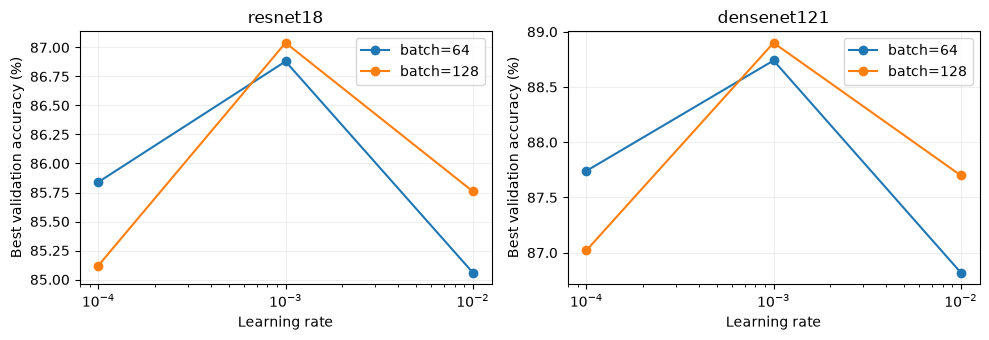

In [4]:
view.lr_search(RUN, OUT)

## 4. Các trial fine-tune đã hoàn tất
Bảng ghi optimizer, LR riêng backbone/head, phạm vi mở tầng, scheduler, validation, epoch thực chạy, thời gian và lý do dừng. Màu xanh lá trong báo cáo gộp đánh dấu cấu hình được chọn; không suy rộng kết luận ra tổ hợp chưa thử.

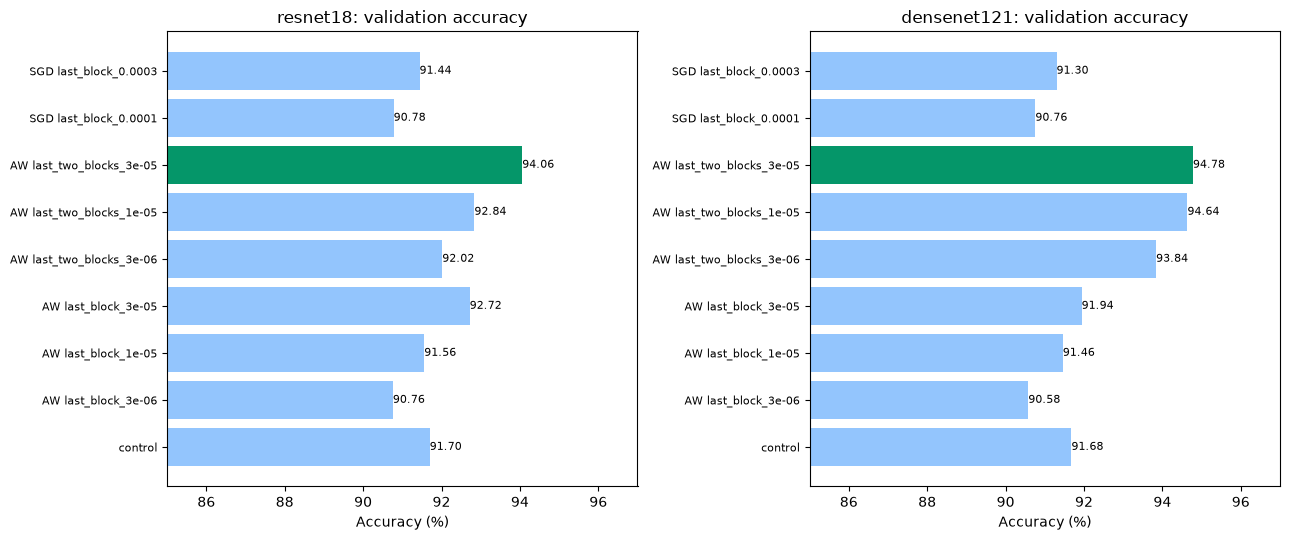

,model,id,optimizer,backbone_lr,head_lr,unfreeze,scheduler,best_val_accuracy,best_val_loss,epochs_completed,best_epoch,train_seconds,stop_reason,selected
0,resnet18,control,adamw,0.00001,0.00010,last_block,none,0.9170,0.33580,13,13,2016.56237,validation_loss_patience,False
1,resnet18,adamw_last_block_3e-06,adamw,0.00000,0.00003,last_block,cosine,0.9076,0.28919,20,20,3121.69011,validation_loss_patience,False
2,resnet18,adamw_last_block_1e-05,adamw,0.00001,0.00010,last_block,cosine,0.9156,0.31941,13,12,2033.97053,validation_loss_patience,False
3,densenet121,control,adamw,0.00001,0.00010,last_block,none,0.9168,0.28712,18,16,4695.40676,validation_loss_patience,False
4,densenet121,adamw_last_block_3e-06,adamw,0.00000,0.00003,last_block,cosine,0.9058,0.29236,30,30,7934.14379,validation_loss_patience,False
5,densenet121,adamw_last_block_1e-05,adamw,0.00001,0.00010,last_block,cosine,0.9146,0.28394,19,17,4886.88979,validation_loss_patience,False
6,resnet18,adamw_last_block_3e-05,adamw,0.00003,0.00030,last_block,cosine,0.9272,0.26256,11,6,1740.97085,validation_loss_patience,False
7,resnet18,adamw_last_two_blocks_3e-06,adamw,0.00000,0.00003,last_two_blocks,cosine,0.9202,0.26296,15,14,2639.65006,validation_loss_patience,False
8,resnet18,adamw_last_two_blocks_1e-05,adamw,0.00001,0.00010,last_two_blocks,cosine,0.9284,0.31158,11,11,1938.21997,validation_loss_patience,False
9,densenet121,adamw_last_block_3e-05,adamw,0.00003,0.00030,last_block,cosine,0.9194,0.28592,12,8,3140.44689,validation_loss_patience,False


In [5]:
merged.grid_results(ROOT, OUT, RUN)

## 5. Head và fine-tune: đường cong và overfit
Hai hàng là hai giai đoạn riêng, Train/Validation có màu riêng; ngôi sao đánh dấu checkpoint theo validation accuracy/loss. Ngân sách tối đa, epoch thực chạy và checkpoint epoch có thể khác nhau.

,Model,Stage,Recorded epochs,Original configured budget,Stop evidence,Separate tuning budget
0,resnet18,Head,10,10,epoch_budget_exhausted,10
1,resnet18,Fine-tune,10,30,validation_loss_patience,"min 10, max 30"
2,densenet121,Head,10,10,epoch_budget_exhausted,10
3,densenet121,Fine-tune,10,30,validation_loss_patience,"min 10, max 30"


,Model,Fine epochs,Val loss: first -> last,Last train-val gap (pp),Convergence
0,resnet18,10,0.2376 -> 0.2822,5.92,not established; more validation history needed
1,densenet121,10,0.1910 -> 0.2206,5.12,not established; more validation history needed


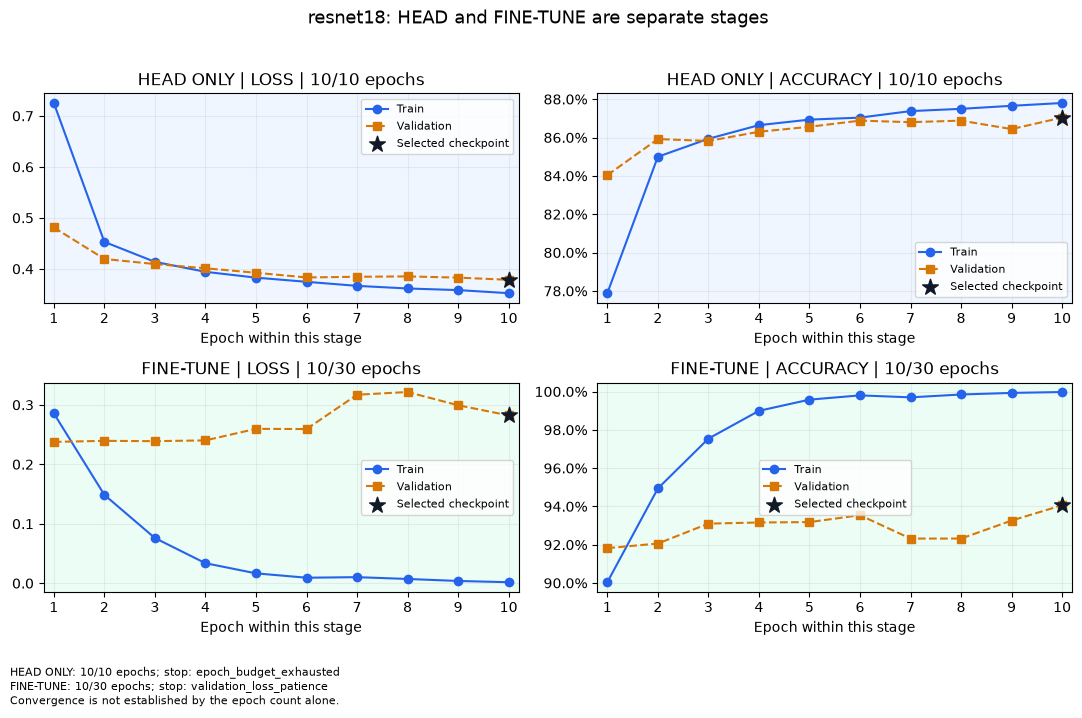

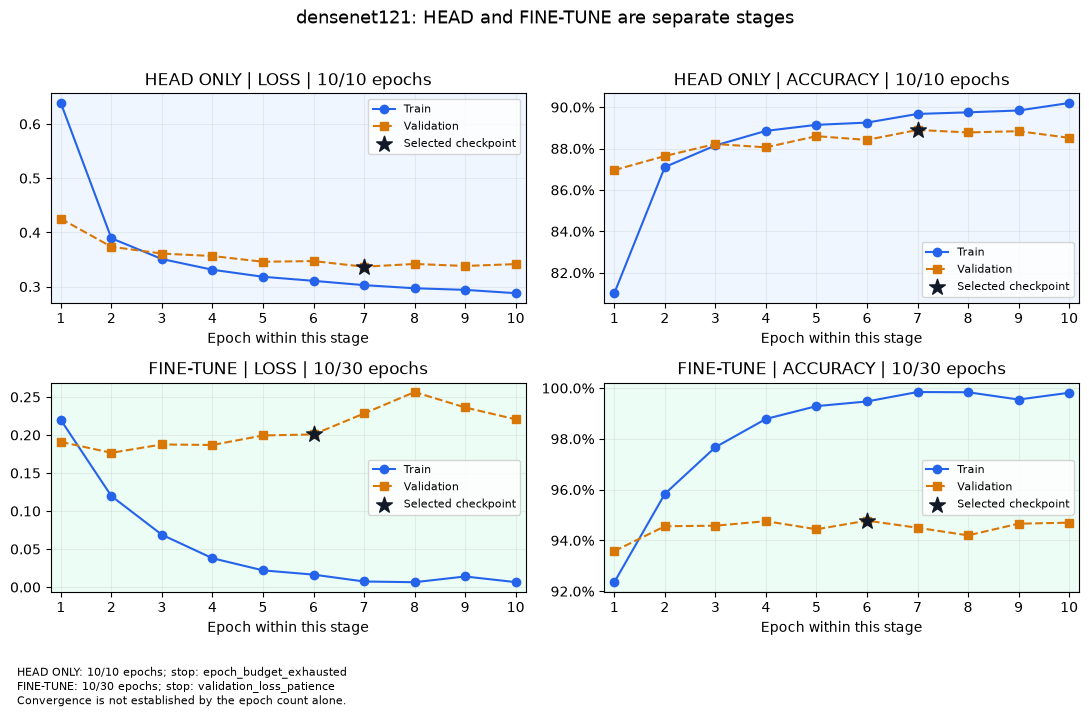

**resnet18**: chạy 10/30 epoch, checkpoint epoch 10; stop: `validation_loss_patience`. Train/validation accuracy cuối 99.98%/94.06%; val loss 0.2376 → 0.2822. Có dấu hiệu overfit: train loss giảm nhưng val loss tăng.

**densenet121**: chạy 10/30 epoch, checkpoint epoch 6; stop: `validation_loss_patience`. Train/validation accuracy cuối 99.82%/94.70%; val loss 0.1910 → 0.2206. Có dấu hiệu overfit: train loss giảm nhưng val loss tăng.

In [6]:
view.epoch_budget(RUN, ROOT)
view.learning_curves(RUN, OUT)
merged.explain(RUN, 'training')

## 6. Precision, Recall/TPR, F1 và FPR theo lớp
Metric được tính từ confusion counts của tập test, đủ lớp cho head và fine-tune. Cặp cat/dog có hình dáng tương tự; ảnh raw 32×32 thiếu chi tiết là giả thuyết thị giác, chưa phải nguyên nhân đã kiểm định.

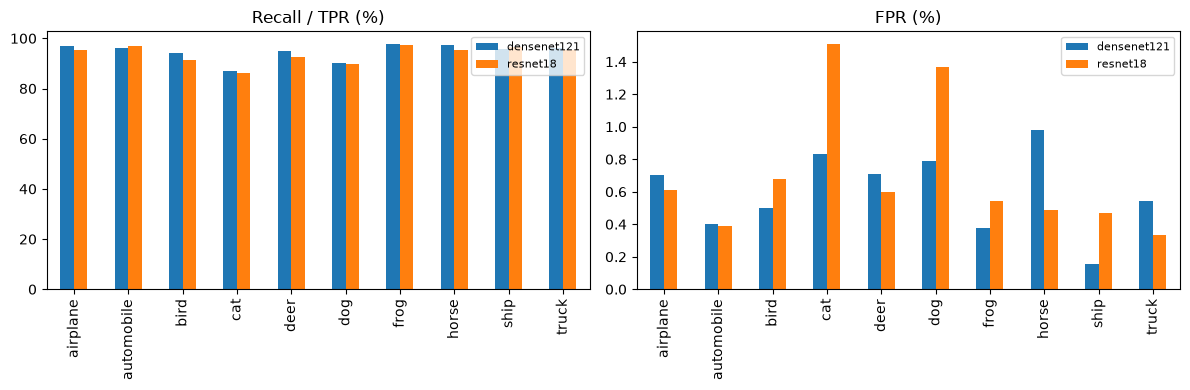

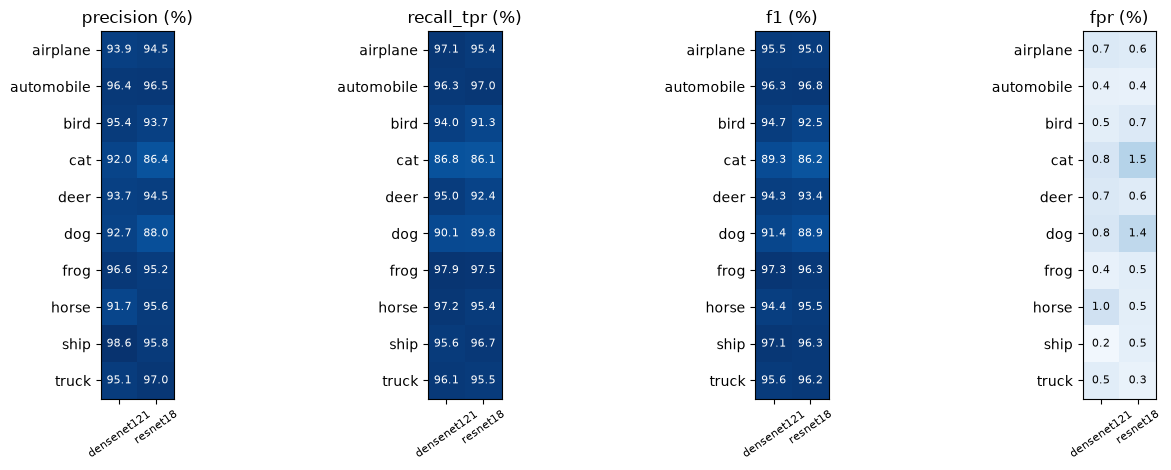

,model,stage,class,precision,recall_tpr,f1,fpr
0,resnet18,head,airplane,0.8346,0.888,0.8605,0.0196
1,resnet18,head,automobile,0.9369,0.921,0.9289,0.0069
2,resnet18,head,bird,0.8022,0.811,0.8066,0.0222
3,resnet18,head,cat,0.7279,0.789,0.7572,0.0328
4,resnet18,head,deer,0.7882,0.871,0.8276,0.0260
5,resnet18,head,dog,0.8792,0.750,0.8095,0.0114
6,resnet18,head,frog,0.9065,0.902,0.9043,0.0103
7,resnet18,head,horse,0.8935,0.831,0.8611,0.0110
8,resnet18,head,ship,0.9167,0.913,0.9148,0.0092
9,resnet18,head,truck,0.9295,0.910,0.9197,0.0077


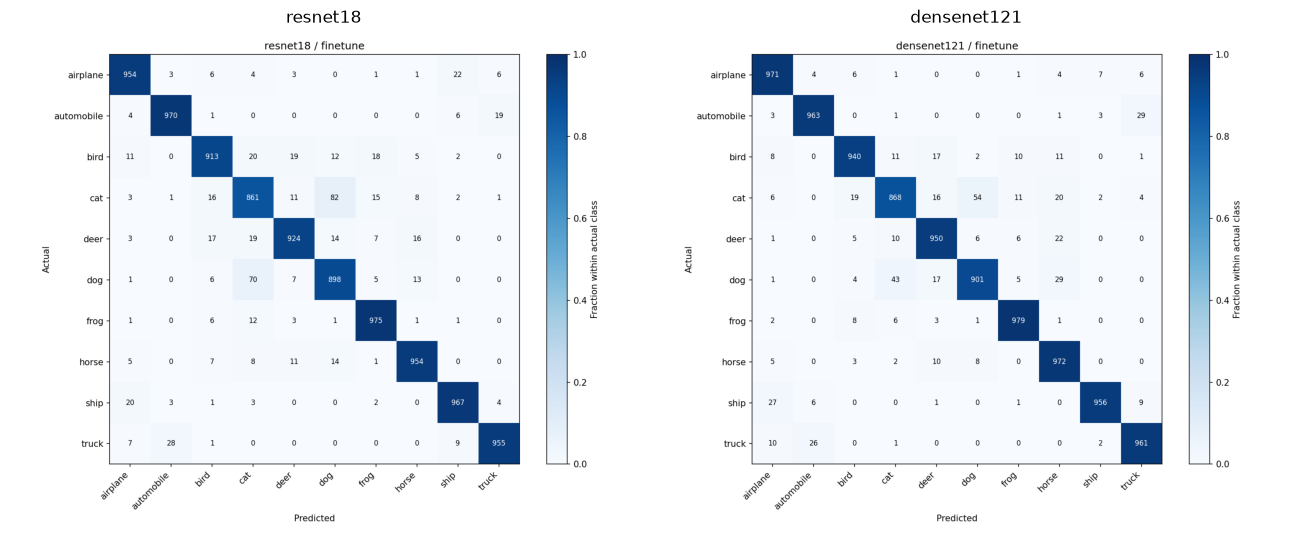

**resnet18**: cat → dog 82 ảnh; dog → cat 70 ảnh. Recall cat 86.10%.

**densenet121**: cat → dog 54 ảnh; dog → cat 43 ảnh. Recall cat 86.80%.

In [7]:
view.errors(RUN, OUT)
view.evidence(RUN, 'confusion_matrix')
merged.explain(RUN, 'errors')

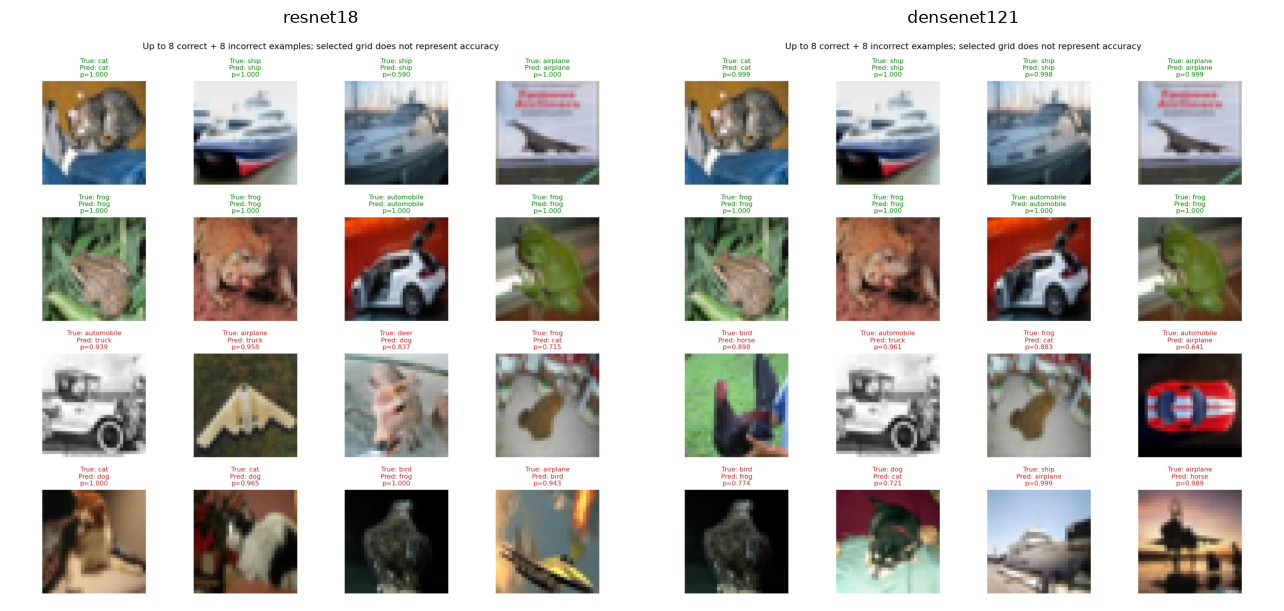

resnet18: cat → dog, p=1.000.

resnet18: bird → frog, p=1.000.

densenet121: ship → airplane, p=0.999.

densenet121: airplane → horse, p=0.989.

Lưới tối đa 8 đúng và 8 sai không đại diện accuracy; confidence cao không bảo đảm đúng.

In [8]:
view.evidence(RUN, 'prediction_examples')
merged.explain(RUN, 'predictions')

## 7. TensorBoard và kiểm chứng save/load
Hình dựng từ scalar events đã lưu, không phải ảnh chụp phiên train trực tiếp. Roundtrip ghi số mẫu và sai số kiểm chứng; không suy diễn thành đánh giá lại toàn test.

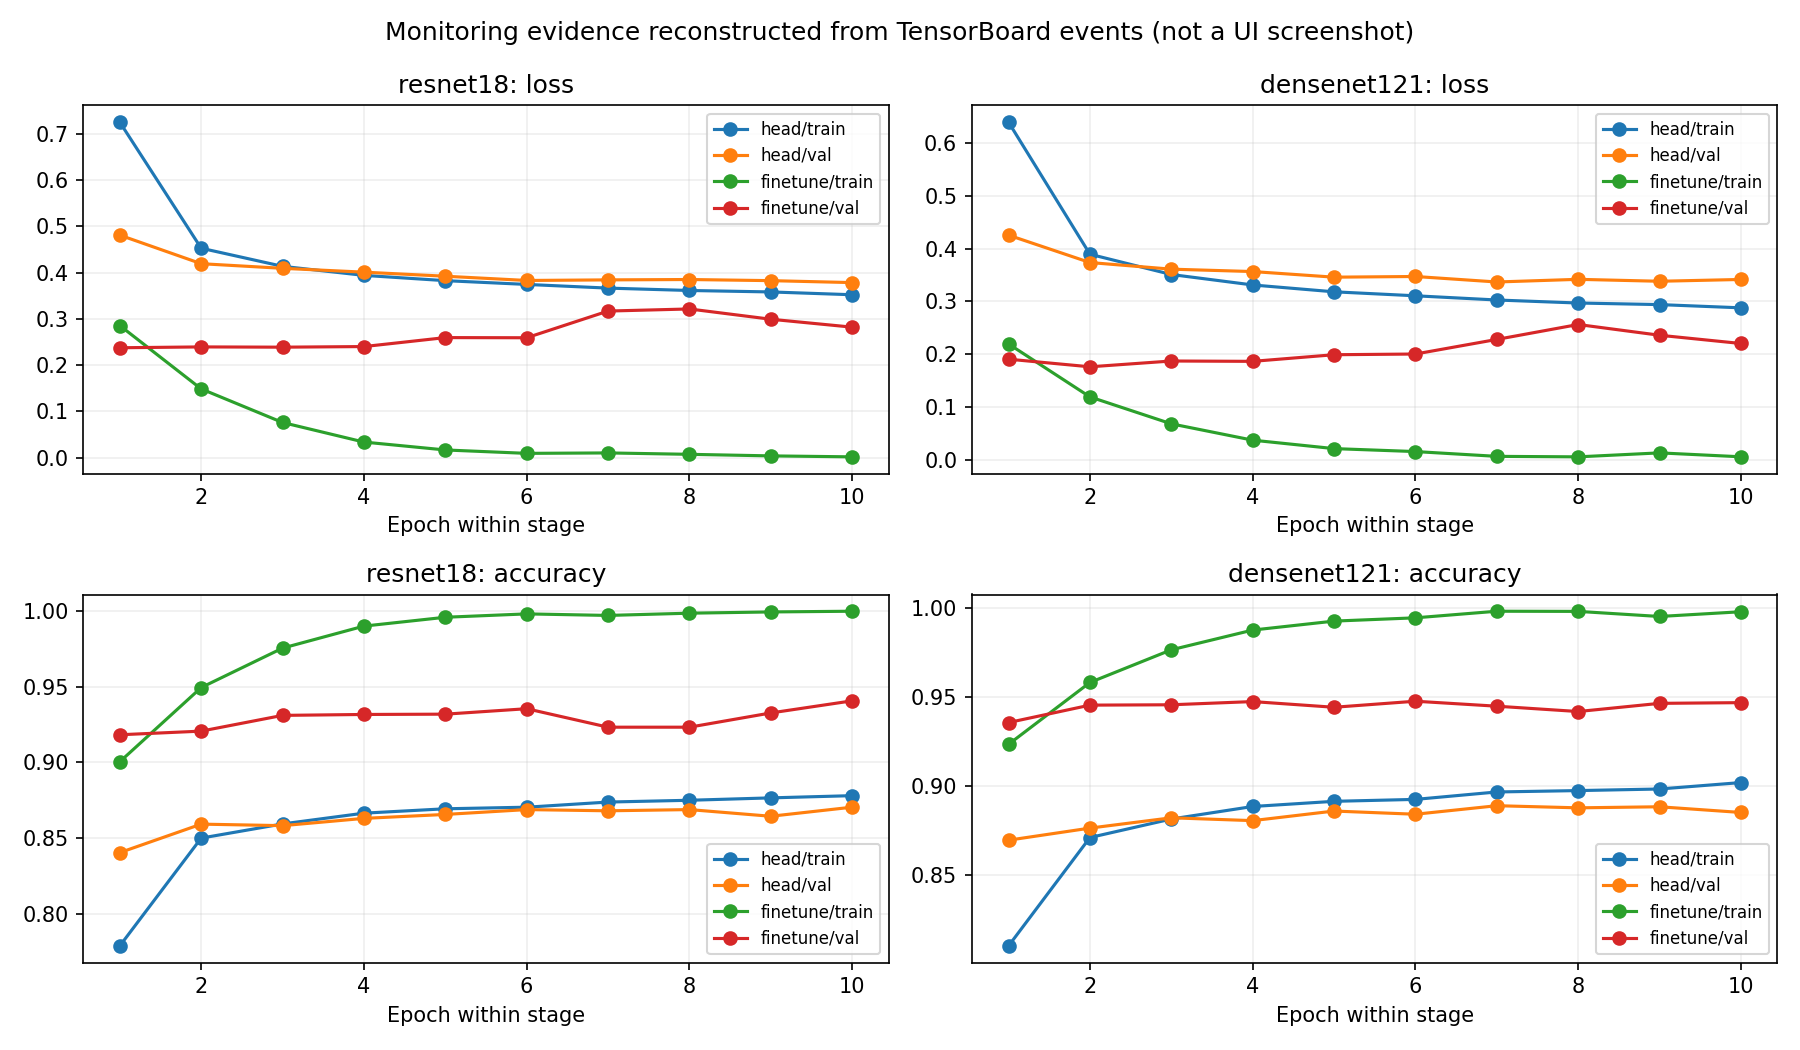

,model,stage,samples,max_probability_error,passed
0,resnet18,head,8,0.0,True
1,resnet18,finetune,8,0.0,True
2,densenet121,head,8,0.0,True
3,densenet121,finetune,8,0.0,True


In [9]:
view.tensorboard_evidence(RUN)
view.roundtrip(RUN)

## Kết luận
Kết luận lấy từ validation của đúng run đang xem. Một seed chưa đủ chứng minh ưu thế thống kê; không tăng epoch chỉ để giảm train loss.

In [10]:
merged.explain(RUN, 'conclusion')

Khuyến nghị theo validation: **densenet121**. Đọc chất lượng cùng thời gian, bộ nhớ và execution policy. Augmentation/dropout là hướng thử tiếp, chưa được đo trong các kết quả này.